# Laboratorio 4 · EDA de INVACOM_DW
**Universidad Técnica Nacional · ISW-911 Minería de Datos**

**Integrantes:** Gaudy Yuliana Chacón Alpizar, Joab Mauricio Montero Montero, Ignacio Araya Rojas y Stuarth Fabricio Miranda Rojas.

Fuente: esquema estrella INVACOM_DW (FACT_VENTAS, DIM_PRODUCTO, DIM_CLIENTE, DIM_TIEMPO). Una fila por pedido y producto. Se usa el DW por solicitud del equipo en sustitución del conjunto abierto de Costa Rica indicado en el enunciado.

## 1–3. Python, fuente y lectura desde GitHub
La extracción de Oracle está publicada con manifiesto SHA-256. El commit fijo contiene ambos archivos. Por defecto se descargan de GitHub; la variable `LAB4_LOCAL_DIR` permite ejecutar una prueba sin red con una copia idéntica verificada por hash. No hay acceso a Northwind ni generación de datos ficticios.

In [1]:
import os, io, json, hashlib, urllib.request, re, unicodedata
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor
%matplotlib inline
REF_GIT = "59b90ec4a45c9d40731f49990f3df39ece7fcc73"
BASE = f"https://raw.githubusercontent.com/nachoar24/workshop-4-mineria-datos/{REF_GIT}/datos/invacom_dw/"
LOCAL = os.environ.get("LAB4_LOCAL_DIR")
def leer(archivo):
    if LOCAL:
        return (Path(LOCAL) / archivo).read_bytes()
    with urllib.request.urlopen(BASE + archivo, timeout=60) as respuesta:
        return respuesta.read()
manifest = json.loads(leer("manifest.json"))
raw = leer("invacom_dw_ventas.csv")
assert manifest["source"] == "Oracle INVACOM_DW"
assert hashlib.sha256(raw).hexdigest() == manifest["sha256"] == "d8fcb1539f76b36b9210d2a08e51df3e9ae371482e929b808fadedad033adc7d"
datos_origen = pd.read_csv(io.BytesIO(raw), dtype="string", keep_default_na=False, na_values=[""])
assert len(datos_origen) == manifest["rows"]
assert not datos_origen.duplicated(["ID_PEDIDO","ID_PRODUCTO"]).any()
assert datos_origen.ID_FACT_VENTA.is_unique
print("Modo:", "copia local verificada" if LOCAL else "GitHub", "| SHA-256:", manifest["sha256"])
print("Extracción:", manifest["extracted_at_utc"], "| Dimensiones:", datos_origen.shape, "| Pedidos:", datos_origen.ID_PEDIDO.nunique())

Modo: copia local verificada | SHA-256: d8fcb1539f76b36b9210d2a08e51df3e9ae371482e929b808fadedad033adc7d
Extracción: 2026-11-26T20:56:15.680460+00:00 | Dimensiones: (2155, 16) | Pedidos: 830


## 4. Características básicas
Se inspeccionan dimensiones, primeras y últimas filas, muestra, tipos, estadísticas y cardinalidades.

In [2]:
print(datos_origen.shape)
display(datos_origen.head(), datos_origen.tail(3), datos_origen.sample(3, random_state=42))
datos_origen.info()
display(datos_origen.describe(include="all").T, datos_origen.nunique().to_frame("distintos"))

(2155, 16)


,ID_FACT_VENTA,ID_PEDIDO,ID_PRODUCTO,ID_CLIENTE,FECHA_PEDIDO,ANIO,MES,PRODUCTO,CATEGORIA,CLIENTE,CIUDAD_CLIENTE,PAIS_CLIENTE,CANTIDAD_VENDIDA,IMPORTE_BRUTO,IMPORTE_DESCUENTO,IMPORTE_NETO
0,1,10248,11,VINET,1996-07-04,1996,7,Queso Cabrales,Dairy Products,Vins et alcools Chevalier,Reims,France,12,168.0,0.0,168.0
1,2,10248,42,VINET,1996-07-04,1996,7,Singaporean Hokkien Fried Mee,Grains/Cereals,Vins et alcools Chevalier,Reims,France,10,98.0,0.0,98.0
2,3,10248,72,VINET,1996-07-04,1996,7,Mozzarella di Giovanni,Dairy Products,Vins et alcools Chevalier,Reims,France,5,174.0,0.0,174.0
3,4,10249,14,TOMSP,1996-07-05,1996,7,Tofu,Produce,Toms Spezialitäten,Münster,Germany,9,167.4,0.0,167.4
4,5,10249,51,TOMSP,1996-07-05,1996,7,Manjimup Dried Apples,Produce,Toms Spezialitäten,Münster,Germany,40,1696.0,0.0,1696.0


,ID_FACT_VENTA,ID_PEDIDO,ID_PRODUCTO,ID_CLIENTE,FECHA_PEDIDO,ANIO,MES,PRODUCTO,CATEGORIA,CLIENTE,CIUDAD_CLIENTE,PAIS_CLIENTE,CANTIDAD_VENDIDA,IMPORTE_BRUTO,IMPORTE_DESCUENTO,IMPORTE_NETO
2152,2153,11077,73,RATTC,1998-05-06,1998,5,Röd Kaviar,Seafood,Rattlesnake Canyon Grocery,Albuquerque,USA,2,30.0,0.3,29.7
2153,2154,11077,75,RATTC,1998-05-06,1998,5,Rhönbräu Klosterbier,Beverages,Rattlesnake Canyon Grocery,Albuquerque,USA,4,31.0,0.0,31.0
2154,2155,11077,77,RATTC,1998-05-06,1998,5,Original Frankfurter grüne Soße,Condiments,Rattlesnake Canyon Grocery,Albuquerque,USA,2,26.0,0.0,26.0


,ID_FACT_VENTA,ID_PEDIDO,ID_PRODUCTO,ID_CLIENTE,FECHA_PEDIDO,ANIO,MES,PRODUCTO,CATEGORIA,CLIENTE,CIUDAD_CLIENTE,PAIS_CLIENTE,CANTIDAD_VENDIDA,IMPORTE_BRUTO,IMPORTE_DESCUENTO,IMPORTE_NETO
1506,1507,10826,31,BLONP,1998-01-12,1998,1,Gorgonzola Telino,Dairy Products,Blondesddsl père et fils,Strasbourg,France,35,437.5,0.0,437.5
1917,1918,10990,34,ERNSH,1998-04-01,1998,4,Sasquatch Ale,Beverages,Ernst Handel,Graz,Austria,60,840.0,126.0,714.0
889,890,10580,14,OTTIK,1997-06-26,1997,6,Tofu,Produce,Ottilies Käseladen,Köln,Germany,15,348.75,17.44,331.31


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2155 entries, 0 to 2154
Data columns (total 16 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   ID_FACT_VENTA      2155 non-null   string
 1   ID_PEDIDO          2155 non-null   string
 2   ID_PRODUCTO        2155 non-null   string
 3   ID_CLIENTE         2155 non-null   string
 4   FECHA_PEDIDO       2155 non-null   string
 5   ANIO               2155 non-null   string
 6   MES                2155 non-null   string
 7   PRODUCTO           2155 non-null   string
 8   CATEGORIA          2155 non-null   string
 9   CLIENTE            2155 non-null   string
 10  CIUDAD_CLIENTE     2155 non-null   string
 11  PAIS_CLIENTE       2155 non-null   string
 12  CANTIDAD_VENDIDA   2155 non-null   string
 13  IMPORTE_BRUTO      2155 non-null   string
 14  IMPORTE_DESCUENTO  2155 non-null   string
 15  IMPORTE_NETO       2155 non-null   string
dtypes: string(16)
memory usage: 269.5 KB


,count,unique,top,freq
ID_FACT_VENTA,2155,2155,1,1
ID_PEDIDO,2155,830,11077,25
ID_PRODUCTO,2155,77,59,54
ID_CLIENTE,2155,89,SAVEA,116
FECHA_PEDIDO,2155,480,1998-05-06,32
ANIO,2155,3,1997,1059
MES,2155,12,4,261
PRODUCTO,2155,77,Raclette Courdavault,54
CATEGORIA,2155,8,Beverages,404
CLIENTE,2155,89,Save-a-lot Markets,116


,distintos
ID_FACT_VENTA,2155
ID_PEDIDO,830
ID_PRODUCTO,77
ID_CLIENTE,89
FECHA_PEDIDO,480
ANIO,3
MES,12
PRODUCTO,77
CATEGORIA,8
CLIENTE,89


## 5. Nombres en español
Los nombres del DW ya están en español salvo la clave de origen, traducida en SQL. Se uniforman a minúsculas y se conserva el término año como `anio`.

In [3]:
nombres = {c: c.lower() for c in datos_origen.columns}
display(pd.DataFrame(nombres.items(),columns=["original","español"]))
datos = datos_origen.rename(columns=nombres).apply(lambda c: c.str.strip()).replace(r"^\s*$", pd.NA, regex=True)
assert datos.columns.is_unique

,original,español
0,ID_FACT_VENTA,id_fact_venta
1,ID_PEDIDO,id_pedido
2,ID_PRODUCTO,id_producto
3,ID_CLIENTE,id_cliente
4,FECHA_PEDIDO,fecha_pedido
5,ANIO,anio
6,MES,mes
7,PRODUCTO,producto
8,CATEGORIA,categoria
9,CLIENTE,cliente


## 6. Valores nulos
Se cuantifican las ausencias sin introducir nulos artificiales. La ausencia de nulos es un resultado válido del ETL.

,nulos,porcentaje
id_fact_venta,0,0.0
id_pedido,0,0.0
id_producto,0,0.0
id_cliente,0,0.0
fecha_pedido,0,0.0
anio,0,0.0
mes,0,0.0
producto,0,0.0
categoria,0,0.0
cliente,0,0.0


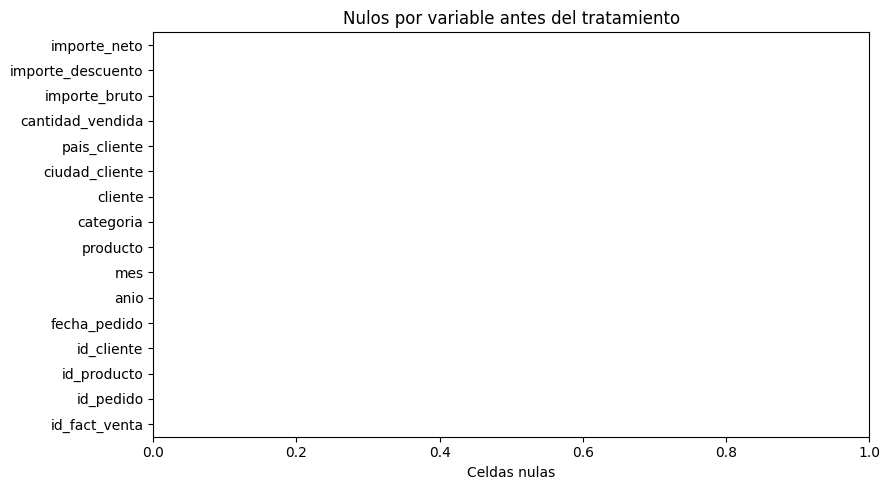

Total: 0


In [4]:
nulos = datos.isna().sum()
display(pd.DataFrame({"nulos":nulos,"porcentaje":100*nulos/len(datos)}))
ax=nulos.plot.barh(figsize=(9,5),title="Nulos por variable antes del tratamiento")
ax.set_xlabel("Celdas nulas"); ax.set_xlim(0,max(1,int(nulos.max())+1)); plt.tight_layout(); plt.show()
print("Total:",nulos.sum())

## 9. Conversión de tipos (antes de analizar atípicos)
Las claves numéricas y cantidades son enteros, las fechas ISO se convierten a datetime y los importes se conservan en su escala original. Se calculan precio y tasa derivados únicamente para descripción; no serán predictores.

In [5]:
importes=["importe_bruto","importe_descuento","importe_neto"]
for c in ["id_fact_venta","id_pedido","id_producto","cantidad_vendida","anio","mes"]:
    v=pd.to_numeric(datos[c],errors="raise"); assert v.notna().all() and (v%1==0).all(); datos[c]=v.astype("int64")
for c in importes: datos[c]=pd.to_numeric(datos[c],errors="raise").astype(float)
datos["fecha_pedido"]=pd.to_datetime(datos.fecha_pedido,format="%Y-%m-%d",errors="raise")
assert datos.cantidad_vendida.gt(0).all() and datos.importe_bruto.ge(0).all()
assert datos.importe_descuento.between(0,datos.importe_bruto).all()
assert datos.importe_neto.ge(0).all() and np.allclose(datos.importe_bruto-datos.importe_descuento,datos.importe_neto,atol=.005,rtol=0)
assert datos.anio.eq(datos.fecha_pedido.dt.year).all() and datos.mes.eq(datos.fecha_pedido.dt.month).all()
datos["dia_semana"]=datos.fecha_pedido.dt.dayofweek
datos["precio_unitario"]=datos.importe_bruto/datos.cantidad_vendida
datos["tasa_descuento"]=datos.importe_descuento/datos.importe_bruto.replace(0,np.nan)
display(datos.dtypes.to_frame("tipo"),datos[["cantidad_vendida","precio_unitario","tasa_descuento"]+importes].describe())

,tipo
id_fact_venta,int64
id_pedido,int64
id_producto,int64
id_cliente,string[python]
fecha_pedido,datetime64[ns]
anio,int64
mes,int64
producto,string[python]
categoria,string[python]
cliente,string[python]


,cantidad_vendida,precio_unitario,tasa_descuento,importe_bruto,importe_descuento,importe_neto
count,2155.000000,2155.000000,2155.000000,2155.000000,2155.000000,2155.000000
mean,23.812993,26.218520,0.056168,628.519067,41.144237,587.374831
std,19.022047,29.827418,0.083451,1036.466980,133.993878,969.224247
min,1.000000,2.000000,0.000000,4.800000,0.000000,4.800000
25%,10.000000,12.000000,0.000000,154.000000,0.000000,147.000000
50%,20.000000,18.400000,0.000000,360.000000,0.000000,337.750000
75%,30.000000,32.000000,0.100000,722.250000,30.560000,656.000000
max,130.000000,263.500000,0.250097,15810.000000,2108.000000,15810.000000


## 7. Valores atípicos
Se utiliza IQR (Q1 − 1,5 IQR; Q3 + 1,5 IQR). Las ventas extremas válidas se conservan: eliminar o imputar cantidades legítimas distorsionaría la demanda y los totales.

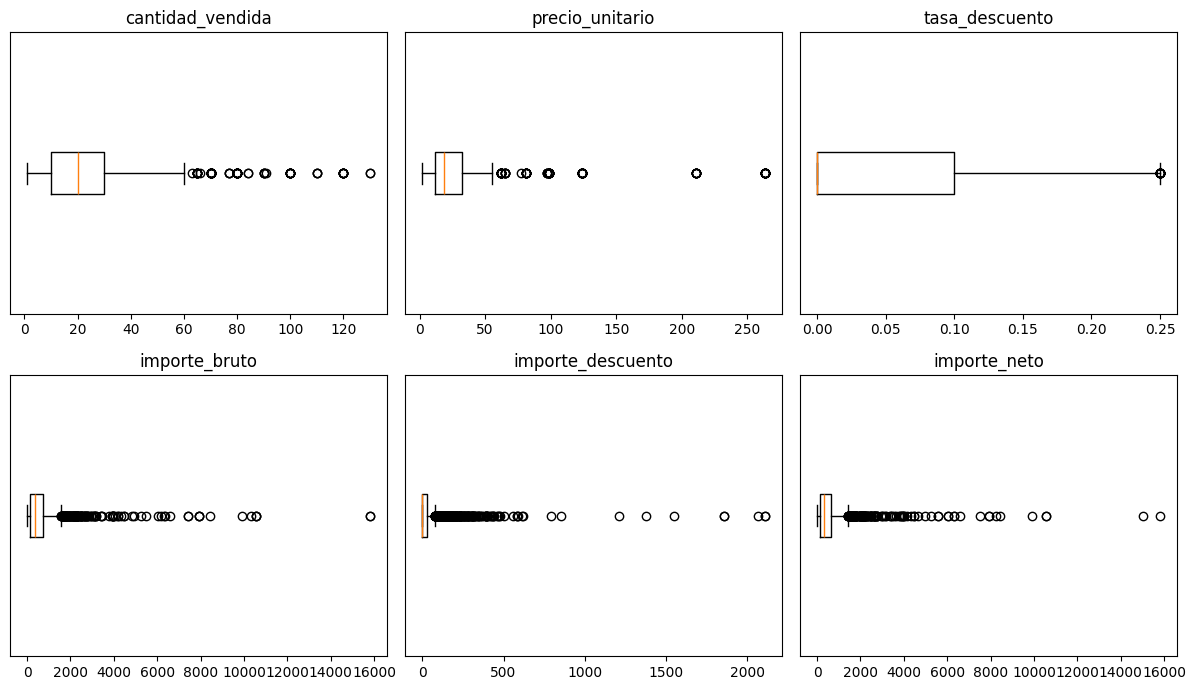

,variable,inferior,superior,atipicos
0,cantidad_vendida,-20.000,60.000,87
1,precio_unitario,-18.000,62.000,98
2,tasa_descuento,-0.150,0.250,20
3,importe_bruto,-698.375,1574.625,163
4,importe_descuento,-45.840,76.400,314
5,importe_neto,-616.500,1419.500,170


In [6]:
def detectar_atipicos_iqr(s):
    q1,q3=s.dropna().quantile([.25,.75]); iqr=q3-q1; lo=q1-1.5*iqr; hi=q3+1.5*iqr
    return ((s<lo)|(s>hi)).fillna(False),lo,hi
medidas=["cantidad_vendida","precio_unitario","tasa_descuento"]+importes
fig,axes=plt.subplots(2,3,figsize=(12,7)); informe=[]
for ax,c in zip(axes.flat,medidas):
    marca,lo,hi=detectar_atipicos_iqr(datos[c]); informe.append([c,lo,hi,int(marca.sum())]); ax.boxplot(datos[c].dropna(),orientation="horizontal"); ax.set_title(c); ax.set_yticks([])
fig.tight_layout(); plt.show(); display(pd.DataFrame(informe,columns=["variable","inferior","superior","atipicos"]))

## 8. Funciones de imputación
Las categorías desconocidas se etiquetan Sin información. La mediana se reserva para variables numéricas opcionales; los importes, claves y cantidad son obligatorios y se validan en lugar de inventarlos. Una tasa indefinida por bruto cero se marca y se representa como cero solo para descripción. Los atípicos válidos no se modifican.

Tasas indefinidas: 0


,antes,despues
id_fact_venta,0,0
id_pedido,0,0
id_producto,0,0
id_cliente,0,0
fecha_pedido,0,0
anio,0,0
mes,0,0
producto,0,0
categoria,0,0
cliente,0,0


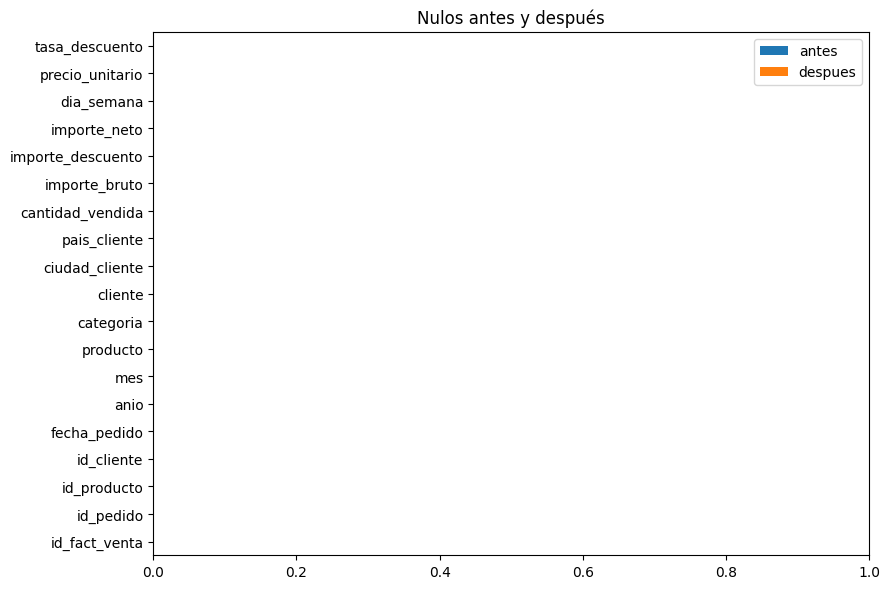

In [7]:
def imputar_categoricas(df,cols):
    copia=df.copy(); copia[cols]=copia[cols].fillna("Sin información"); return copia
def imputar_mediana(df,cols):
    copia=df.copy(); copia[cols]=copia[cols].fillna(copia[cols].median()); return copia
cats=["producto","categoria","cliente","ciudad_cliente","pais_cliente"]
assert not datos[["id_fact_venta","id_pedido","id_producto","id_cliente","fecha_pedido","cantidad_vendida"]+importes].isna().any().any()
antes=datos.isna().sum(); limpios=imputar_categoricas(datos,cats); limpios=imputar_mediana(limpios,["precio_unitario"])
print("Tasas indefinidas:",limpios.tasa_descuento.isna().sum()); limpios["tasa_descuento"]=limpios.tasa_descuento.fillna(0)
for c in cats: limpios[c]=limpios[c].astype("category")
comparacion=pd.DataFrame({"antes":antes,"despues":limpios.isna().sum()}); display(comparacion)
ax=comparacion.plot.barh(figsize=(9,6),title="Nulos antes y después"); ax.set_xlim(0,max(1,int(antes.max())+1)); plt.tight_layout(); plt.show()
assert not limpios.isna().any().any()

## Conciliación de métricas
Se preservan los importes oficiales de FACT_VENTAS y se comparan con los totales reales del manifiesto.

lineas          2155.00
unidades       51317.00
bruto        1354458.59
descuento      88665.83
neto         1265792.76
Name: total conciliado, dtype: float64

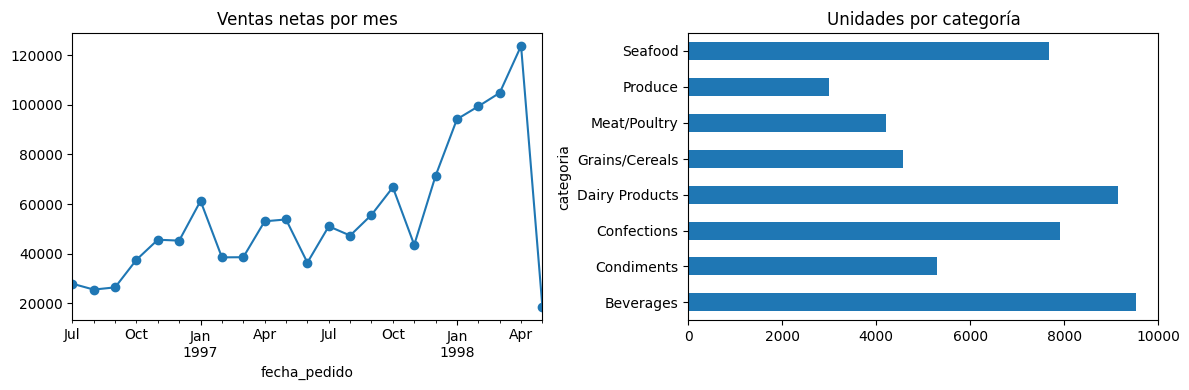

In [8]:
totales={"lineas":len(limpios),"unidades":int(limpios.cantidad_vendida.sum()),"bruto":limpios.importe_bruto.sum(),"descuento":limpios.importe_descuento.sum(),"neto":limpios.importe_neto.sum()}
for k,v in totales.items(): assert np.isclose(v,float(manifest["totals"][k]),atol=.005,rtol=0),k
display(pd.Series(totales,name="total conciliado"))
fig,ax=plt.subplots(1,2,figsize=(12,4)); limpios.groupby(limpios.fecha_pedido.dt.to_period("M")).importe_neto.sum().plot(ax=ax[0],marker="o",title="Ventas netas por mes"); limpios.groupby("categoria",observed=True).cantidad_vendida.sum().plot.barh(ax=ax[1],title="Unidades por categoría"); fig.tight_layout(); plt.show()

## 10. Variables categóricas
One-hot encoding para producto, categoría, país y ciudad; el mes y el día de semana se codifican cíclicamente. Identificadores e importes derivados de la cantidad quedan excluidos de los predictores.

In [9]:
categoricas_modelo=["producto","categoria","pais_cliente","ciudad_cliente"]
indicadores=pd.get_dummies(limpios[categoricas_modelo],prefix_sep="__",dtype="uint8")
def normalizar_nombre(s):
    s=unicodedata.normalize("NFKD",s).encode("ascii","ignore").decode(); return re.sub(r"[^a-z0-9_]+","_",s.lower()).strip("_")
indicadores.columns=[normalizar_nombre(c) for c in indicadores.columns]
assert indicadores.columns.is_unique
predictores=limpios[["anio"]].copy()
for c,periodo,inicio in [("mes",12,1),("dia_semana",7,0)]:
    a=2*np.pi*(limpios[c]-inicio)/periodo; predictores[c+"_seno"]=np.sin(a); predictores[c+"_coseno"]=np.cos(a)
predictores=pd.concat([predictores,indicadores],axis=1); objetivo=limpios.cantidad_vendida.copy()
print("Predictores:",predictores.shape); display(predictores.head())

Predictores: (2155, 181)


,anio,mes_seno,mes_coseno,dia_semana_seno,dia_semana_coseno,producto__alice_mutton,producto__aniseed_syrup,producto__boston_crab_meat,producto__camembert_pierrot,producto__carnarvon_tigers,producto__chai,producto__chang,producto__chartreuse_verte,producto__chef_anton_s_cajun_seasoning,producto__chef_anton_s_gumbo_mix,producto__chocolade,producto__cote_de_blaye,producto__escargots_de_bourgogne,producto__filo_mix,producto__flotemysost,producto__geitost,producto__genen_shouyu,producto__gnocchi_di_nonna_alice,producto__gorgonzola_telino,producto__grandma_s_boysenberry_spread,producto__gravad_lax,producto__guarana_fantastica,producto__gudbrandsdalsost,producto__gula_malacca,producto__gumbar_gummibarchen,producto__gustaf_s_knackebrod,producto__ikura,producto__inlagd_sill,producto__ipoh_coffee,producto__jack_s_new_england_clam_chowder,producto__konbu,producto__lakkalikoori,producto__laughing_lumberjack_lager,producto__longlife_tofu,producto__louisiana_fiery_hot_pepper_sauce,...,ciudad_cliente__koln,ciudad_cliente__lander,ciudad_cliente__leipzig,ciudad_cliente__lille,ciudad_cliente__lisboa,ciudad_cliente__london,ciudad_cliente__lulea,ciudad_cliente__lyon,ciudad_cliente__madrid,ciudad_cliente__mannheim,ciudad_cliente__marseille,ciudad_cliente__montreal,ciudad_cliente__mexico_d_f,ciudad_cliente__munchen,ciudad_cliente__munster,ciudad_cliente__nantes,ciudad_cliente__oulu,ciudad_cliente__paris,ciudad_cliente__portland,ciudad_cliente__reggio_emilia,ciudad_cliente__reims,ciudad_cliente__resende,ciudad_cliente__rio_de_janeiro,ciudad_cliente__salzburg,ciudad_cliente__san_cristobal,ciudad_cliente__san_francisco,ciudad_cliente__sao_paulo,ciudad_cliente__seattle,ciudad_cliente__sevilla,ciudad_cliente__stavern,ciudad_cliente__strasbourg,ciudad_cliente__stuttgart,ciudad_cliente__torino,ciudad_cliente__toulouse,ciudad_cliente__tsawassen,ciudad_cliente__vancouver,ciudad_cliente__versailles,ciudad_cliente__walla_walla,ciudad_cliente__warszawa,ciudad_cliente__arhus
0,1996,1.224647e-16,-1.0,0.433884,-0.900969,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,1996,1.224647e-16,-1.0,0.433884,-0.900969,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,1996,1.224647e-16,-1.0,0.433884,-0.900969,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,1996,1.224647e-16,-1.0,-0.433884,-0.900969,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,1996,1.224647e-16,-1.0,-0.433884,-0.900969,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


## 11. Estandarización
StandardScaler sobre el año. Indicadores binarios y cíclicos ya tienen escalas acotadas; cantidad vendida queda sin modificar. Los importes oficiales se preservan en auditoría. Se muestran además las medidas comerciales estandarizadas para el EDA descriptivo, no para entrenar. En una futura evaluación se ajustarán los transformadores solo con entrenamiento.

,media_z,desviacion_z
cantidad_vendida,-6.099787e-17,1.0
precio_unitario,-5.275491e-17,1.0
tasa_descuento,-6.511935e-17,1.0
importe_bruto,-6.594364e-17,1.0
importe_descuento,5.110632e-17,1.0
importe_neto,-2.308027e-17,1.0


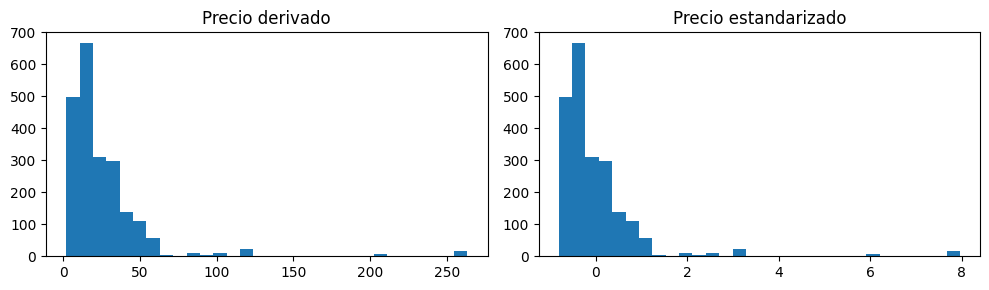

In [10]:
esc=StandardScaler(); predictores_z=predictores.drop(columns="anio").copy(); predictores_z["anio_z"]=esc.fit_transform(predictores[["anio"]]).ravel()
medidas_z=pd.DataFrame(StandardScaler().fit_transform(limpios[medidas]),columns=medidas,index=limpios.index)
display(pd.DataFrame({"media_z":medidas_z.mean(),"desviacion_z":medidas_z.std(ddof=0)}))
fig,ax=plt.subplots(1,2,figsize=(10,3)); ax[0].hist(limpios.precio_unitario,bins=30); ax[0].set_title("Precio derivado"); ax[1].hist(medidas_z.precio_unitario,bins=30); ax[1].set_title("Precio estandarizado"); fig.tight_layout(); plt.show()

## 12. Correlación
Pearson sobre medidas comerciales y asociaciones de predictores con el objetivo. Las correlaciones entre importes y cantidades reflejan también relaciones aritméticas y no implican causalidad.

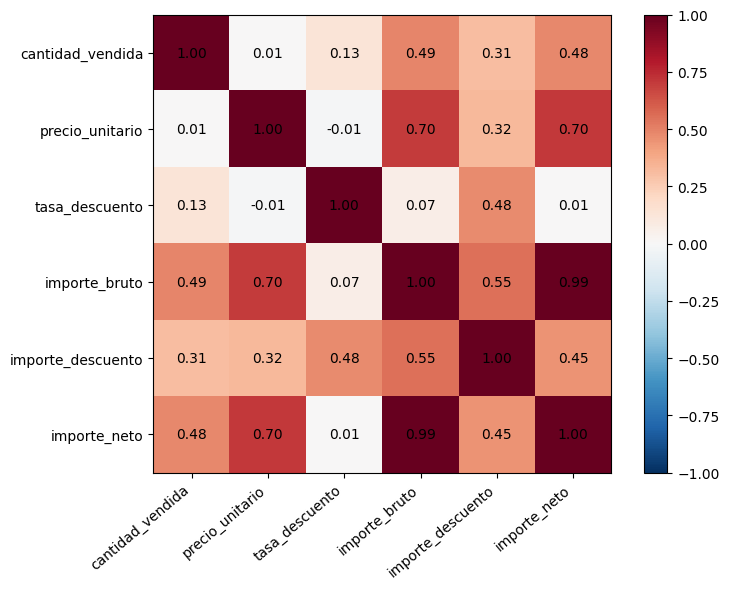

,cantidad_vendida,precio_unitario,tasa_descuento,importe_bruto,importe_descuento,importe_neto
cantidad_vendida,1.0000,0.0074,0.1286,0.4887,0.3091,0.4799
precio_unitario,0.0074,1.0000,-0.0112,0.6998,0.3246,0.7035
tasa_descuento,0.1286,-0.0112,1.0000,0.0676,0.4752,0.0066
importe_bruto,0.4887,0.6998,0.0676,1.0000,0.5502,0.9933
importe_descuento,0.3091,0.3246,0.4752,0.5502,1.0000,0.4501
importe_neto,0.4799,0.7035,0.0066,0.9933,0.4501,1.0000


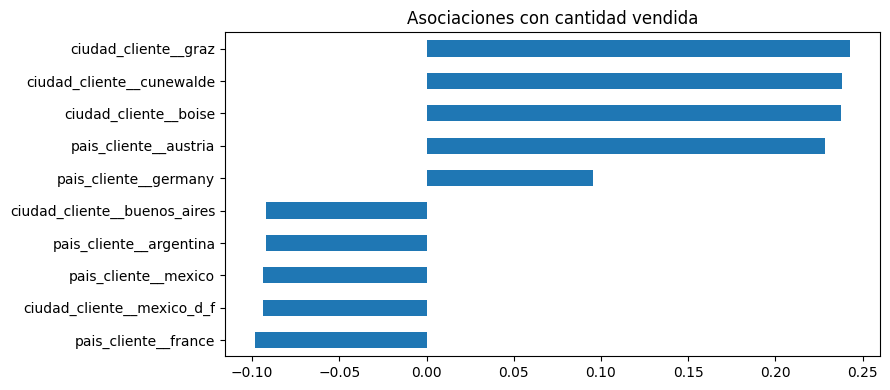

,r
ciudad_cliente__graz,0.242923
ciudad_cliente__cunewalde,0.238478
ciudad_cliente__boise,0.237398
pais_cliente__austria,0.228644
pais_cliente__france,-0.098456
pais_cliente__germany,0.095256
ciudad_cliente__mexico_d_f,-0.093624
pais_cliente__mexico,-0.093624
pais_cliente__argentina,-0.092156
ciudad_cliente__buenos_aires,-0.092156


In [11]:
matriz=limpios[medidas].corr(); fig,ax=plt.subplots(figsize=(8,6)); im=ax.imshow(matriz,cmap="RdBu_r",vmin=-1,vmax=1); ax.set_xticks(range(len(medidas)),medidas,rotation=40,ha="right"); ax.set_yticks(range(len(medidas)),medidas)
for i in range(len(medidas)):
    for j in range(len(medidas)): ax.text(j,i,f"{matriz.iloc[i,j]:.2f}",ha="center",va="center")
fig.colorbar(im,ax=ax); fig.tight_layout(); plt.show(); display(matriz.round(4))
corr=predictores_z.corrwith(objetivo).dropna(); top=corr.reindex(corr.abs().sort_values(ascending=False).head(10).index); top.sort_values().plot.barh(figsize=(9,4),title="Asociaciones con cantidad vendida"); plt.tight_layout(); plt.show(); display(top.to_frame("r"))

## 13. Variable dependiente y modelo candidato
**Cantidad vendida por línea** (regresión). Un árbol de decisión de regresión permite representar relaciones no lineales entre producto, ubicación y calendario. Se excluyen los importes y precio/tasa derivados, pues pueden introducir información de la cantidad ya observada. El escenario supone que los atributos del pedido son conocidos antes de predecir su cantidad. No es un pronóstico agregado de ventas. En una evaluación futura se separará por pedido o fecha, ajustando el preprocesamiento en entrenamiento y midiendo MAE y RMSE. No se exige entrenar el modelo en este laboratorio.

In [12]:
modelo=DecisionTreeRegressor(max_depth=5,min_samples_leaf=15,random_state=42)
print("Objetivo:",objetivo.name,"| Candidato:",modelo)
assert not set(importes+["precio_unitario","tasa_descuento","cantidad_vendida"]).intersection(predictores_z.columns)

Objetivo: cantidad_vendida | Candidato: DecisionTreeRegressor(max_depth=5, min_samples_leaf=15, random_state=42)


## 14. Exportación
Se guardan los predictores, objetivo e identificadores e importes para auditoría. Las columnas de auditoría no se deben utilizar al entrenar.

In [13]:
auditoria=limpios[["id_fact_venta","id_pedido","id_producto"]+importes].copy()
procesados=pd.concat([auditoria,predictores_z,objetivo],axis=1)
assert len(procesados)==len(datos_origen) and not procesados.duplicated(["id_pedido","id_producto"]).any()
assert not procesados.isna().any().any() and np.isfinite(procesados.to_numpy(dtype=float)).all()
procesados.to_csv("data_process.csv",index=False,encoding="utf-8",float_format="%.10g")
check=pd.read_csv("data_process.csv"); assert check.shape==procesados.shape and check.columns.tolist()==procesados.columns.tolist() and np.allclose(check,procesados,rtol=1e-8,atol=1e-9)
print("data_process.csv:",check.shape,"| Nulos:",check.isna().sum().sum(),"| Unidades:",check.cantidad_vendida.sum(),"| Neto:",round(check.importe_neto.sum(),2)); display(check.head())

data_process.csv: (2155, 188) | Nulos: 0 | Unidades: 51317 | Neto: 1265792.76


,id_fact_venta,id_pedido,id_producto,importe_bruto,importe_descuento,importe_neto,mes_seno,mes_coseno,dia_semana_seno,dia_semana_coseno,producto__alice_mutton,producto__aniseed_syrup,producto__boston_crab_meat,producto__camembert_pierrot,producto__carnarvon_tigers,producto__chai,producto__chang,producto__chartreuse_verte,producto__chef_anton_s_cajun_seasoning,producto__chef_anton_s_gumbo_mix,producto__chocolade,producto__cote_de_blaye,producto__escargots_de_bourgogne,producto__filo_mix,producto__flotemysost,producto__geitost,producto__genen_shouyu,producto__gnocchi_di_nonna_alice,producto__gorgonzola_telino,producto__grandma_s_boysenberry_spread,producto__gravad_lax,producto__guarana_fantastica,producto__gudbrandsdalsost,producto__gula_malacca,producto__gumbar_gummibarchen,producto__gustaf_s_knackebrod,producto__ikura,producto__inlagd_sill,producto__ipoh_coffee,producto__jack_s_new_england_clam_chowder,...,ciudad_cliente__leipzig,ciudad_cliente__lille,ciudad_cliente__lisboa,ciudad_cliente__london,ciudad_cliente__lulea,ciudad_cliente__lyon,ciudad_cliente__madrid,ciudad_cliente__mannheim,ciudad_cliente__marseille,ciudad_cliente__montreal,ciudad_cliente__mexico_d_f,ciudad_cliente__munchen,ciudad_cliente__munster,ciudad_cliente__nantes,ciudad_cliente__oulu,ciudad_cliente__paris,ciudad_cliente__portland,ciudad_cliente__reggio_emilia,ciudad_cliente__reims,ciudad_cliente__resende,ciudad_cliente__rio_de_janeiro,ciudad_cliente__salzburg,ciudad_cliente__san_cristobal,ciudad_cliente__san_francisco,ciudad_cliente__sao_paulo,ciudad_cliente__seattle,ciudad_cliente__sevilla,ciudad_cliente__stavern,ciudad_cliente__strasbourg,ciudad_cliente__stuttgart,ciudad_cliente__torino,ciudad_cliente__toulouse,ciudad_cliente__tsawassen,ciudad_cliente__vancouver,ciudad_cliente__versailles,ciudad_cliente__walla_walla,ciudad_cliente__warszawa,ciudad_cliente__arhus,anio_z,cantidad_vendida
0,1,10248,11,168.0,0.0,168.0,1.224647e-16,-1.0,0.433884,-0.900969,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,-1.616562,12
1,2,10248,42,98.0,0.0,98.0,1.224647e-16,-1.0,0.433884,-0.900969,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,-1.616562,10
2,3,10248,72,174.0,0.0,174.0,1.224647e-16,-1.0,0.433884,-0.900969,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,-1.616562,5
3,4,10249,14,167.4,0.0,167.4,1.224647e-16,-1.0,-0.433884,-0.900969,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,-1.616562,9
4,5,10249,51,1696.0,0.0,1696.0,1.224647e-16,-1.0,-0.433884,-0.900969,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,-1.616562,40


## 15–16. Entrega
Integrantes en el encabezado. Entregar `lab4_IC2025.ipynb` y conservar `data_process.csv` en GitHub. La validación local usa una copia de la extracción idéntica por SHA-256 a la publicada.